# Musky habitat conditions at Longtail Point: 573 ft lake floor

Evaluate every scenario in `michiganhuron_avg.csv` at a fixed lake-floor elevation of **573 ft IGLD85** (174.6504 m).

| Component | Monthly conditions | Qualifying unit |
| --- | --- | --- |
| Juvenile habitat | Depth **> 0.3 m** (strict), May-August | All 4 months pass -> qualifying year |
| Spawning zones | Depth **0.3-1.5 m** (inclusive), May-June | Both months pass -> qualifying year |
| Recruitment zones | Depth **0.3-0.6 m** (inclusive), May-June | Both months pass -> *recruitment year*; a **rolling 5-year window** qualifies when **>= 3** of its 5 years are recruitment years |


In [1]:
from pathlib import Path
import sys

ROOT = next((root for root in (Path.cwd(), *Path.cwd().parents)
             if (root / 'pyproject.toml').is_file() and (root / 'hydropattern').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from within the hydropattern repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from climate_canvas.plots_utilities import plot_response_surface
from IPython.display import Markdown, display
from matplotlib.colors import Normalize, TwoSlopeNorm

from hydropattern.parsers import duration_parser, magnitude_parser, timing_parser
from hydropattern.patterns import Component
from hydropattern.scenario_grid import build_grid, parse_scenario_name
from hydropattern.scenarios import evaluate_scenarios
from hydropattern.timeseries import Timeseries

## Units, datum, timing

- Lake levels are monthly averages in **meters, IGLD85**; lake-floor elevations are **feet, IGLD85** (same datum). Conversion: **1 ft = 0.3048 m** exactly; floor elevations are rounded to 4 decimals (exact for integer feet).
- Water depth = lake level - floor elevation. Negative values (floor above the lake) are not clipped and fail every criterion.
- Thresholds are expressed as lake-level elevations (floor + depth). A `1e-9 m` tolerance protects the equality boundaries from floating-point artifacts; levels have 0.01 m resolution, so it cannot change a result. The juvenile `> 0.3 m` limit is strict: a level exactly 0.3 m deep fails.
- Calendar years are used (Jan 1 start). Hydropattern uses a leap-normalized 365-day calendar: May 1 = day 121, Jun 1 = 152, Jul 1 = 182, Aug 1 = 213. Monthly timestamps fall on the first of each month, so juvenile habitat evaluates days 121-243 (4 observations) and spawning/recruitment evaluate days 121-181 (2 observations).
- Monthly averages are used directly (no smoothing or daily interpolation). Passing every monthly mean does not prove the threshold held every day; wind setup, seiche, and intra-month variability are not represented.

## Reporting contract

- Only complete Jan-Dec years are scored; partial end years are excluded. Missing or duplicate timestamps are rejected.
- Components also carry a hydropattern duration gate: all **4 consecutive monthly observations** must meet juvenile criteria; both **2 consecutive monthly observations** must meet spawning/recruitment criteria. Duration counts monthly timesteps, not elapsed days. Annual reporting independently checks every required month.
- **Juvenile / spawning surface value** = `100 x qualifying complete years / complete years`.
- **Recruitment surface value** = `100 x rolling 5-year windows with >=3 recruitment years / all full 5-year windows`. Windows overlap and partial windows at the record ends are excluded, so it is a window percentage, not a year percentage.
- An unknown annual verdict (not expected: all levels are finite) would give a range of possible percentages; the plotted value is then the **midpoint** and the `Midpoint used` column is flagged. The notebook prints whether this rule was needed.
- These are depth-only habitat screens; they are not a validated musky population model (temperature, vegetation, ice-out, wave exposure, and substrate are outside this analysis).

In [2]:
# ---- Units and datum -------------------------------------------------------
# Lake levels (m, IGLD85) and lake-floor elevations (ft, IGLD85) share a datum.
FT_TO_M = 0.3048                      # exact international foot
DEPTHS_FT = tuple(range(573, 580))    # lake-floor elevations evaluated (ft IGLD85)
EPS = 1e-9                            # float tolerance only; levels have 0.01 m resolution

# ---- Habitat criteria (depths in m) -----------------------------------------
JUVENILE_MIN_DEPTH_M = 0.3            # strictly deeper than
SPAWNING_DEPTH_M = (0.3, 1.5)         # inclusive
RECRUITMENT_DEPTH_M = (0.3, 0.6)      # inclusive
JUVENILE_MONTHS = (5, 6, 7, 8)        # May-Aug, all four must pass
EARLY_MONTHS = (5, 6)                 # May-Jun, both must pass
# Leap-normalized day-of-year: May 1 = 121, Jun 1 = 152, Jul 1 = 182, Aug 1 = 213.
JUVENILE_DOY = (121, 243)
EARLY_DOY = (121, 181)
WINDOW_YEARS, WINDOW_REQUIRED = 5, 3  # recruitment: >=3 successful years per 5

REQUIRED_MONTHS = {'juvenile_habitat': JUVENILE_MONTHS,
                   'spawning_zones': EARLY_MONTHS,
                   'recruitment_zones': EARLY_MONTHS}
COMPONENT_ORDER = tuple(REQUIRED_MONTHS)
COMPONENT_TITLES = {
    'juvenile_habitat': 'Juvenile habitat: depth > 0.3 m in all of May-Aug',
    'spawning_zones': 'Spawning zones: depth 0.3-1.5 m in both May and Jun',
    'recruitment_zones': 'Recruitment zones: depth 0.3-0.6 m in May and Jun, in >=3 of every 5 years',
}
COMPONENT_UNITS = {
    'juvenile_habitat': 'Complete years meeting condition (%)',
    'spawning_zones': 'Complete years meeting condition (%)',
    'recruitment_zones': 'Rolling 5-yr windows with >=3 recruitment years (%)',
}


def bottom_m(bottom_ft: float) -> float:
    return round(bottom_ft * FT_TO_M, 4)


def level_at_depth(bottom_ft: float, depth_m: float) -> float:
    return round(bottom_m(bottom_ft) + depth_m, 4)


def build_components(bottom_ft: float) -> dict[str, Component]:
    def lvl(depth_m):
        return level_at_depth(bottom_ft, depth_m)

    def component(name, doy, magnitude, duration_months):
        return Component(
            name=name,
            characteristics=[
                timing_parser(list(doy), order=1)._replace(name='season'),
                magnitude_parser(magnitude, order=2)._replace(name='depth'),
                duration_parser(['>=', duration_months], order=3)
                ._replace(name='season_duration'),
            ],
            is_success_pattern=True,
        )

    return {
        'juvenile_habitat': component(
            'juvenile_habitat', JUVENILE_DOY,
            ['>', lvl(JUVENILE_MIN_DEPTH_M) + EPS], len(JUVENILE_MONTHS)),
        'spawning_zones': component(
            'spawning_zones', EARLY_DOY,
            [lvl(SPAWNING_DEPTH_M[0]) - EPS, lvl(SPAWNING_DEPTH_M[1]) + EPS],
            len(EARLY_MONTHS)),
        'recruitment_zones': component(
            'recruitment_zones', EARLY_DOY,
            [lvl(RECRUITMENT_DEPTH_M[0]) - EPS, lvl(RECRUITMENT_DEPTH_M[1]) + EPS],
            len(EARLY_MONTHS)),
    }


def complete_year_labels(dates: pd.DatetimeIndex) -> list[int]:
    if dates.hasnans or not dates.is_unique or not dates.is_monotonic_increasing:
        raise ValueError('Monthly timestamps must be valid, unique, and increasing.')
    if len(dates) < 2 or not (dates.day == 1).all() or not np.all(
            np.diff(dates.year * 12 + dates.month) == 1):
        raise ValueError('Expected consecutive monthly observations on the first of each month.')
    counts = pd.Series(dates.year).value_counts().sort_index()
    return counts.index[counts.eq(12)].tolist()


def annual_verdicts(outcomes: pd.Series, required_months: tuple[int, ...]) -> pd.Series:
    # 1 = every required month passed, 0 = any required month failed, NaN = otherwise unknown
    complete = complete_year_labels(outcomes.index)
    if not complete:
        raise ValueError('No complete January-December years are available.')
    verdicts = {}
    for label, year in outcomes.groupby(outcomes.index.year):
        if label not in complete:
            continue
        required = year.loc[year.index.month.isin(required_months)]
        if len(required) != len(required_months):
            raise ValueError('Required monthly observations are not unique and complete.')
        verdicts[int(label)] = (
            0.0 if required.eq(0).any() else 1.0 if required.eq(1).all() else np.nan)
    return pd.Series(verdicts, name=outcomes.name, dtype=float).rename_axis('Year')


def window_verdicts(annual: pd.Series, window: int = WINDOW_YEARS,
                    required: int = WINDOW_REQUIRED) -> pd.Series:
    # Rolling windows of consecutive complete years; partial windows at the record ends are excluded.
    if len(annual) < window or not np.all(np.diff(annual.index) == 1):
        raise ValueError('Rolling windows need consecutive complete years covering a full window.')
    verdicts = {}
    for start in range(len(annual) - window + 1):
        chunk = annual.iloc[start:start + window]
        successes, unknown = int(chunk.eq(1).sum()), int(chunk.isna().sum())
        verdicts[int(chunk.index[0])] = (
            1.0 if successes >= required else 0.0 if successes + unknown < required else np.nan)
    return pd.Series(verdicts, name=annual.name, dtype=float).rename_axis('Window start year')


def verdict_summary(verdicts: pd.Series) -> dict:
    # Unknown verdicts bound the percentage; the plotted value is the midpoint of the bounds.
    total = len(verdicts)
    if total == 0:
        raise ValueError('Percentages require at least one evaluated year or window.')
    successes, unknown = int(verdicts.eq(1).sum()), int(verdicts.isna().sum())
    lower, upper = 100 * successes / total, 100 * (successes + unknown) / total
    return {'Evaluated units': total, 'Successes': successes,
            'Failures': int(verdicts.eq(0).sum()), 'Unknown': unknown,
            'Lower percentage': lower, 'Upper percentage': upper,
            'Percentage': (lower + upper) / 2, 'Midpoint used': unknown > 0}


def load_levels(csv_path):
    ts = Timeseries.from_csv(str(csv_path), first_dowy=1, date_format='%Y-%m-%d')
    names = list(ts.data.columns[:-1])
    values = ts.data[names].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Missing/infinite lake levels cannot be evaluated.')
    if '_0_0' not in names or any(parse_scenario_name(n) is None for n in names):
        raise ValueError('Expected baseline _0_0 and precipitation/temperature scenario names.')
    if not complete_year_labels(ts.data.index):
        raise ValueError('No complete January-December years.')
    return ts, names


def evaluate_depth(ts: Timeseries, scenario_names: list[str], bottom_ft: float) -> pd.DataFrame:
    components = build_components(bottom_ft)
    evaluated = evaluate_scenarios(ts, list(components.values()))
    rows = []
    for key in COMPONENT_ORDER:
        results = evaluated.by_component(key)
        for name in scenario_names:
            annual = annual_verdicts(results[name].df[key], REQUIRED_MONTHS[key])
            scored = window_verdicts(annual) if key == 'recruitment_zones' else annual
            precipitation, temperature = parse_scenario_name(name)
            rows.append({
                'Bottom (ft)': bottom_ft, 'Component': key, 'Scenario': name,
                'Precipitation delta (%)': precipitation, 'Temperature delta (deg C)': temperature,
                'Complete years': len(annual), 'Successful years': int(annual.eq(1).sum()),
                **verdict_summary(scored),
            })
    return pd.DataFrame(rows).set_index(['Component', 'Scenario'])

In [3]:
BOTTOM_FT = 573.0
BOTTOM_M = bottom_m(BOTTOM_FT)
print(f'Floor: {BOTTOM_FT:.0f} ft = {BOTTOM_M:.4f} m IGLD85')
thresholds = pd.DataFrame({
    'Depth criterion (m)': ['> 0.3', '0.3-1.5', '0.3-0.6'],
    'Lake level (m IGLD85)': [f'> {level_at_depth(BOTTOM_FT, 0.3):.4f}',
                              f'{level_at_depth(BOTTOM_FT, 0.3):.4f}-{level_at_depth(BOTTOM_FT, 1.5):.4f}',
                              f'{level_at_depth(BOTTOM_FT, 0.3):.4f}-{level_at_depth(BOTTOM_FT, 0.6):.4f}'],
}, index=['Juvenile habitat', 'Spawning zones', 'Recruitment zones'])
display(thresholds)

Floor: 573 ft = 174.6504 m IGLD85


,Depth criterion (m),Lake level (m IGLD85)
Juvenile habitat,> 0.3,> 174.9504
Spawning zones,0.3-1.5,174.9504-176.1504
Recruitment zones,0.3-0.6,174.9504-175.2504


In [4]:
example = ROOT / 'examples' / 'longtailpoint'
ts, scenario_names = load_levels(example / 'michiganhuron_avg.csv')
dates = ts.data.index
levels = ts.data[scenario_names]
complete_years = complete_year_labels(dates)
print(f'{len(dates):,} monthly averages; {len(complete_years)} complete years '
      f'({complete_years[0]}-{complete_years[-1]}); {len(scenario_names)} scenarios; no missing levels.')
print(f'Lake level range: {levels.to_numpy().min():.2f}-{levels.to_numpy().max():.2f} m IGLD85 '
      f'({levels.to_numpy().min() / FT_TO_M:.2f}-{levels.to_numpy().max() / FT_TO_M:.2f} ft).')

12,360 monthly averages; 1030 complete years (1970-2999); 17 scenarios; no missing levels.


Lake level range: 173.02-178.65 m IGLD85 (567.65-586.12 ft).


## Evaluate all scenarios

In [5]:
summary = evaluate_depth(ts, scenario_names, BOTTOM_FT)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(summary[['Successful years', 'Evaluated units', 'Successes', 'Failures', 'Unknown',
                     'Percentage', 'Midpoint used']].round(2))
midpoint_rows = summary['Midpoint used']
print('Midpoint rule needed for:', 'none (all verdicts definite)' if not midpoint_rows.any()
      else sorted(set(summary.index[midpoint_rows].get_level_values(0))))
display(summary.xs('_0_0', level='Scenario')[
    ['Complete years', 'Successful years', 'Evaluated units', 'Successes', 'Failures', 'Percentage']].round(2))

Successful years  Evaluated units  Successes  \
Component         Scenario                                                 
juvenile_habitat  _0_0                  1030             1030       1030   
                  _0_1.5                1030             1030       1030   
                  _0_3                  1007             1030       1007   
                  _0_5                   541             1030        541   
                  _0_7                    48             1030         48   
                  _5_1.5                1030             1030       1030   
                  _5_3                  1030             1030       1030   
                  _5_5                  1001             1030       1001   
                  _5_7                   510             1030        510   
                  _10_3                 1030             1030       1030   
                  _10_5                 1030             1030       1030   
                  _10_7                  924             1030        924   
                  _15_3                 1030             1030       1030   
                  _15_5                 1030             1030       1030   
                  _15_7                 1028             1030       1028   
                  _20_5                 1030             1030       1030   
                  _20_7                 1030             1030       1030   
spawning_zones    _0_0                    76             1030         76   
                  _0_1.5                 551             1030        551   
                  _0_3                   927             1030        927   
                  _0_5                   539             1030        539   
                  _0_7                    48             1030         48   
                  _5_1.5                  52             1030         52   
                  _5_3                   435             1030        435   
                  _5_5                   923             1030        923   
                  _5_7                   511             1030        511   
                  _10_3                   58             1030         58   
                  _10_5                  560             1030        560   
                  _10_7                  880             1030        880   
                  _15_3                    0             1030          0   
                  _15_5                   72             1030         72   
                  _15_7                  588             1030        588   
                  _20_5                    0             1030          0   
                  _20_7                   60             1030         60   
recruitment_zones _0_0                     0             1026          0   
                  _0_1.5                   0             1026          0   
                  _0_3                   103             1026         54   
                  _0_5                   213             1026        130   
                  _0_7                    31             1026          9   
                  _5_1.5                   0             1026          0   
                  _5_3                     0             1026          0   
                  _5_5                   120             1026         72   
                  _5_7                   212             1026        126   
                  _10_3                    0             1026          0   
                  _10_5                    4             1026          0   
                  _10_7                  180             1026        124   
                  _15_3                    0             1026          0   
                  _15_5                    0             1026          0   
                  _15_7                    8             1026          3   
                  _20_5                    0             1026          0   
                  _20_7                    0             1026          0   


Midpoint rule needed for: none (all verdicts definite)


,Complete years,Successful years,Evaluated units,Successes,Failures,Percentage
Component,,,,,,
juvenile_habitat,1030,1030,1030,1030,0,100.00
spawning_zones,1030,76,1030,76,954,7.38
recruitment_zones,1030,0,1026,0,1026,0.00


## Baseline diagnostics: what limits habitat?

Baseline (`_0_0`) May-August monthly depths against the criteria. Failure categories overlap, so do not add them.

,May,Jun,Jul,Aug
count,1030.000,1030.000,1030.000,1030.000
mean,1.898,1.974,2.005,2.003
std,0.322,0.324,0.323,0.322
min,1.080,1.160,1.190,1.210
25%,1.662,1.740,1.760,1.750
50%,1.890,1.970,2.000,2.000
75%,2.120,2.200,2.230,2.230
max,2.910,3.130,3.200,3.210


Baseline: % of months meeting each depth condition


,depth > 0.3 m,0.3-1.5 m,0.3-0.6 m,depth < 0.3 m,depth > 1.5 m
Month,,,,,
May,100.0,11.7,0.0,0.0,88.3
Jun,100.0,7.4,0.0,0.0,92.6
Jul,100.0,5.3,0.0,0.0,94.7
Aug,100.0,4.9,0.0,0.0,95.1


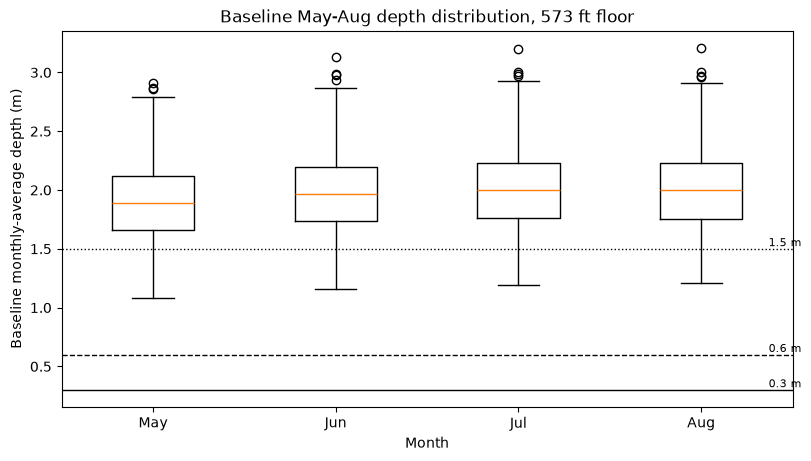

In [6]:
baseline_depth = levels['_0_0'] - BOTTOM_M
season = baseline_depth[baseline_depth.index.month.isin(JUVENILE_MONTHS)]
depth_table = season.groupby([season.index.year, season.index.month]).first().unstack()
depth_table.columns = ['May', 'Jun', 'Jul', 'Aug']
depth_table.index.name = 'Year'
display(depth_table.describe().round(3))
monthly_checks = pd.DataFrame({
    'depth > 0.3 m': season.gt(0.3 + EPS),
    '0.3-1.5 m': season.between(0.3 - EPS, 1.5 + EPS),
    '0.3-0.6 m': season.between(0.3 - EPS, 0.6 + EPS),
    'depth < 0.3 m': season.lt(0.3 - EPS),
    'depth > 1.5 m': season.gt(1.5 + EPS),
})
month_share = (100 * monthly_checks.groupby(season.index.month).mean()).round(1)
month_share.index = ['May', 'Jun', 'Jul', 'Aug']
month_share.index.name = 'Month'
print('Baseline: % of months meeting each depth condition')
display(month_share)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.boxplot([depth_table[m].to_numpy() for m in depth_table.columns], tick_labels=depth_table.columns)
for y, label, style in [(0.3, '0.3 m', '-'), (0.6, '0.6 m', '--'), (1.5, '1.5 m', ':')]:
    ax.axhline(y, color='black', linestyle=style, linewidth=1)
    ax.text(4.55, y, label, va='bottom', ha='right', fontsize=8)
ax.set(ylabel='Baseline monthly-average depth (m)', xlabel='Month',
       title=f'Baseline May-Aug depth distribution, {BOTTOM_FT:.0f} ft floor')
plt.show()
plt.close(fig)

## Scenario response surfaces

Precipitation delta is horizontal; temperature delta is vertical. Each component's unrounded `_0_0` baseline percentage is the color-bar midpoint (white) via `TwoSlopeNorm`; slopes differ below and above the baseline, so compare numeric percentages, not colors, across components or depths. If the baseline is exactly 0% or 100% it cannot be a midpoint; the surface then uses climate-canvas default `RdBu` ramp on a one-sided scale anchored at the baseline and ending at the most extreme observed percentage. Read the colorbar ticks: scale range differs between panels.

Each component is drawn twice: the **raw** grid (absent scenario combinations blank) and an **interpolated / filled** surface. Interpolated values are spatial estimates between supplied scenarios, not additional evaluated scenarios. Colorbar labels state the metric: years (juvenile, spawning) or rolling 5-year windows (recruitment).

### Juvenile habitat: depth > 0.3 m in all of May-Aug

Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,100.00,NaN,NaN,NaN,NaN
1.5,100.00,100.00,NaN,NaN,NaN
3.0,97.77,100.00,100.00,100.00,NaN
5.0,52.52,97.18,100.00,100.00,100.0
7.0,4.66,49.51,89.71,99.81,100.0


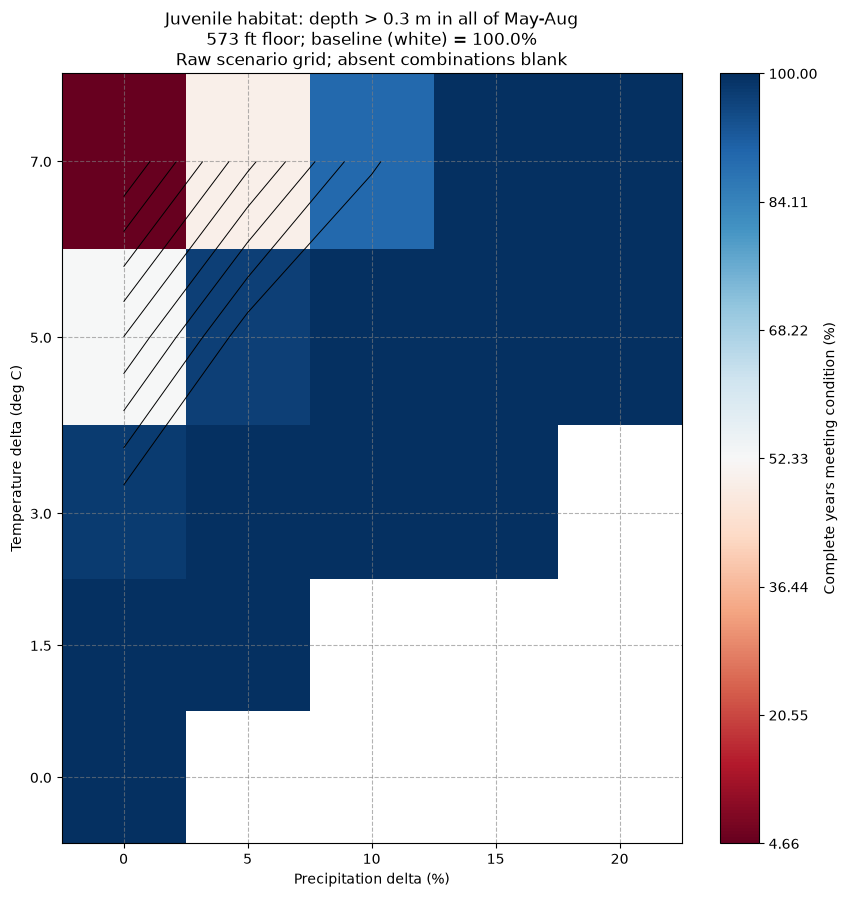

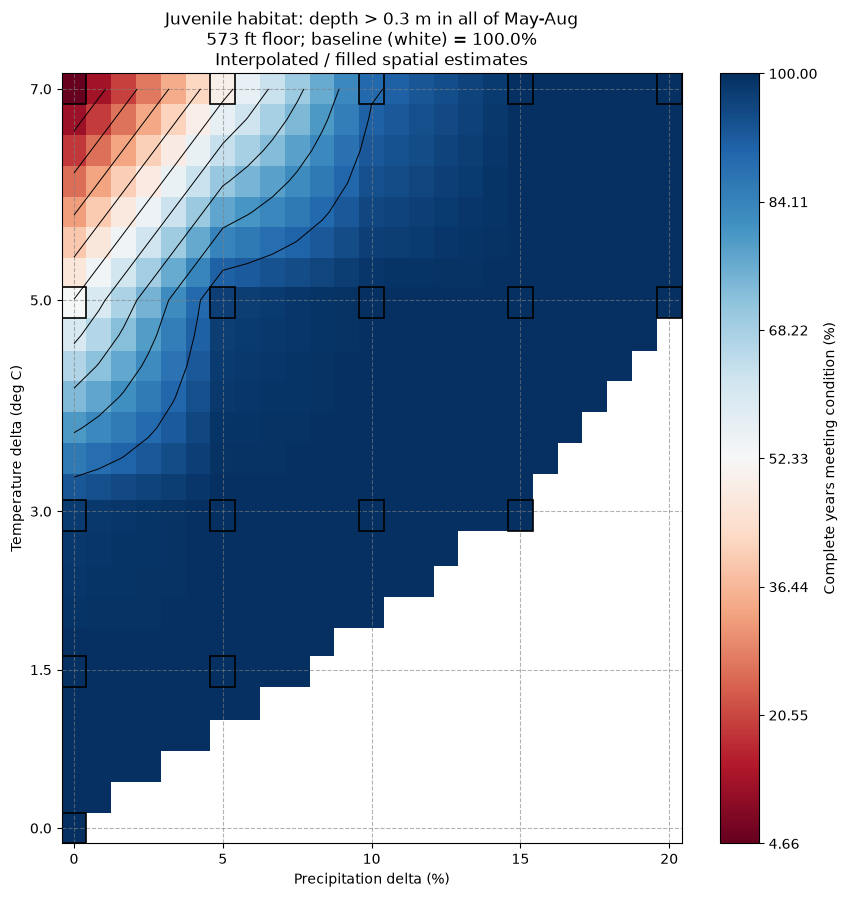

### Spawning zones: depth 0.3-1.5 m in both May and Jun

Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,7.38,NaN,NaN,NaN,NaN
1.5,53.50,5.05,NaN,NaN,NaN
3.0,90.00,42.23,5.63,0.00,NaN
5.0,52.33,89.61,54.37,6.99,0.00
7.0,4.66,49.61,85.44,57.09,5.83


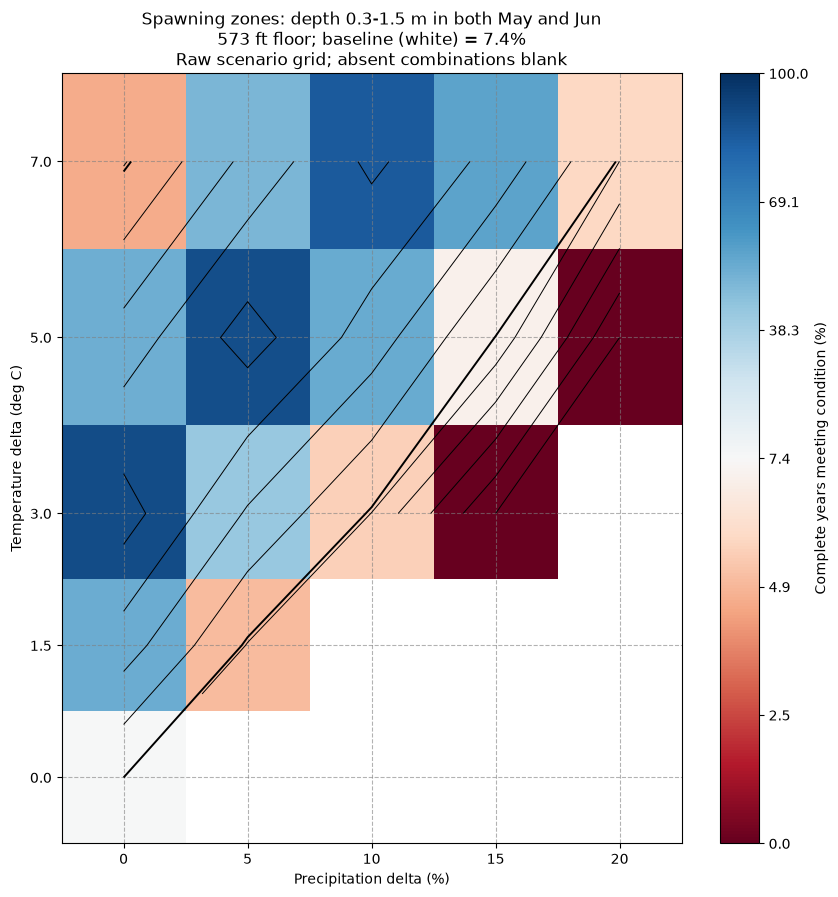

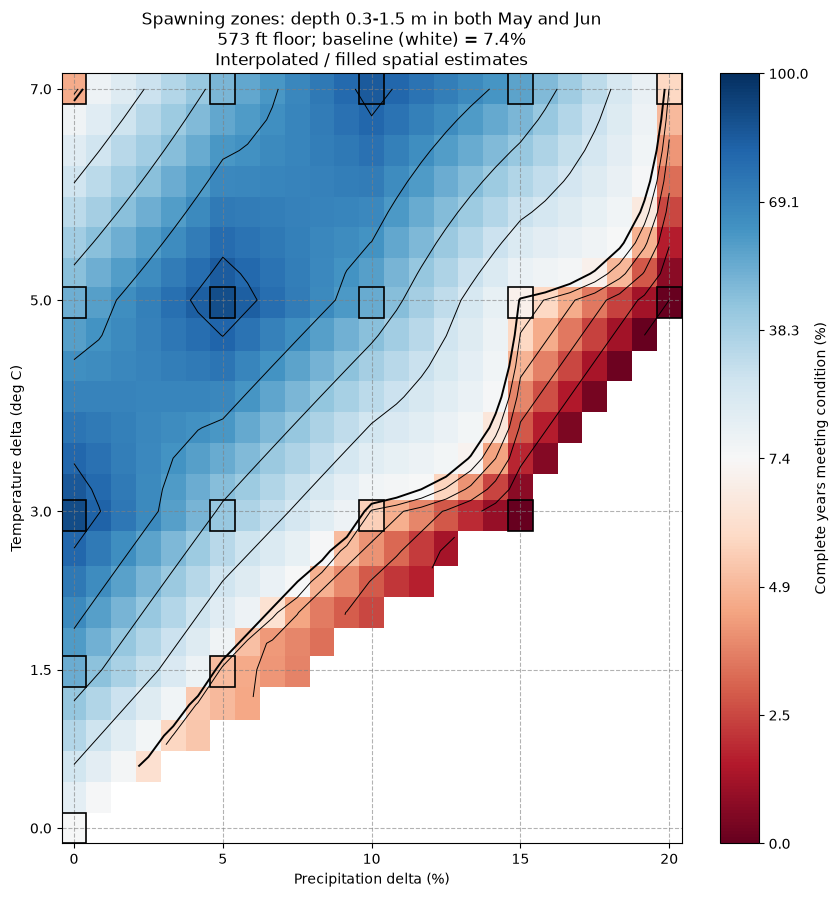

### Recruitment zones: depth 0.3-0.6 m in May and Jun, in >=3 of every 5 years

Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,0.00,NaN,NaN,NaN,NaN
1.5,0.00,0.00,NaN,NaN,NaN
3.0,5.26,0.00,0.00,0.00,NaN
5.0,12.67,7.02,0.00,0.00,0.0
7.0,0.88,12.28,12.09,0.29,0.0


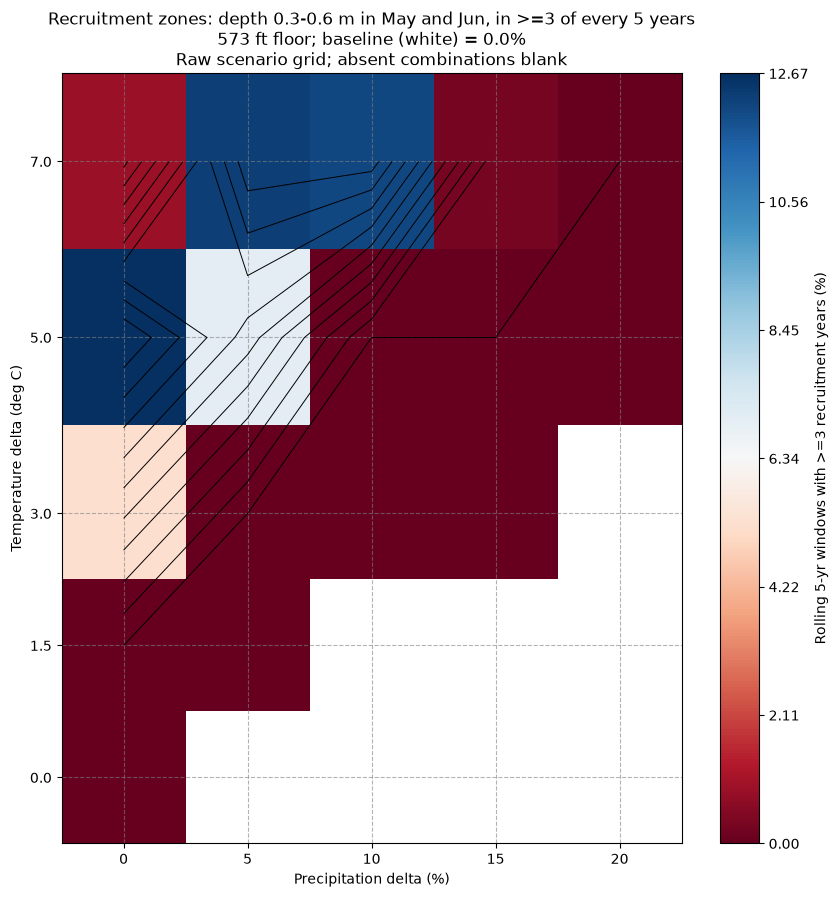

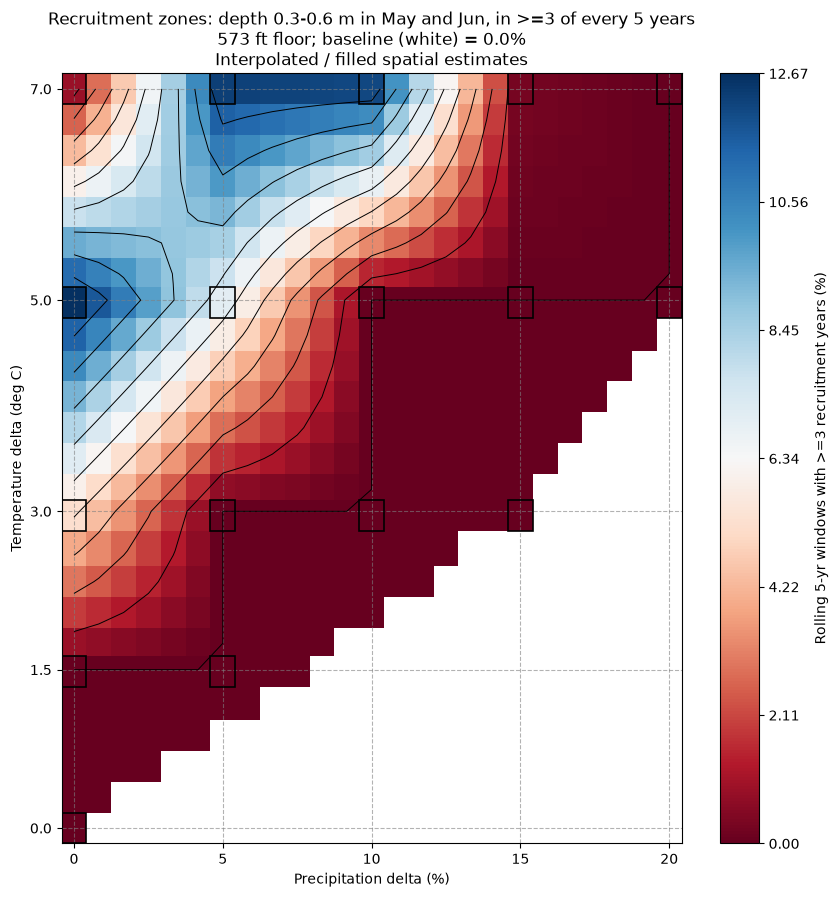

In [7]:
def baseline_scale(baseline_percentage, observed):
    # Interior baseline: diverging scale with the baseline white. Baseline at 0% or 100% cannot be a
    # midpoint, so use a one-sided sequential scale anchored at the baseline and ending at the
    # most extreme observed value (a 0-100% scale would wash out small percentages).
    if not np.isfinite(baseline_percentage) or not 0 <= baseline_percentage <= 100:
        raise ValueError('A known baseline percentage in [0, 100] is required.')
    if 0 < baseline_percentage < 100:
        return TwoSlopeNorm(vmin=0, vcenter=baseline_percentage, vmax=100), 'RdBu', 1.4
    if baseline_percentage == 0:
        return Normalize(vmin=0, vmax=max(float(np.nanmax(observed)), 1.0)), 'RdBu', 0.7
    return Normalize(vmin=min(float(np.nanmin(observed)), 99.0), vmax=100), 'RdBu', 0.7


for key in COMPONENT_ORDER:
    rows = summary.loc[key]
    baseline_percentage = float(rows.loc['_0_0', 'Percentage'])
    precipitation, temperature, grid = build_grid(scenario_names, rows['Percentage'].to_dict())
    norm, color_map, center_width = baseline_scale(baseline_percentage, grid)
    contour_levels = tuple(norm.inverse(np.linspace(0, 1, 11)))
    color_ticks = norm.inverse(np.linspace(0, 1, 7)).tolist()
    display(Markdown(f'### {COMPONENT_TITLES[key]}'))
    display(pd.DataFrame(grid, index=pd.Index(temperature, name='Temperature delta (deg C)'),
                         columns=pd.Index(precipitation, name='Precipitation delta (%)')).round(2))
    for interpolate, subtitle in [(False, 'Raw scenario grid; absent combinations blank'),
                                  (True, 'Interpolated / filled spatial estimates')]:
        plot_response_surface(
            precipitation, temperature, grid.copy(), interpolate=interpolate, fillin=interpolate,
            labels=('Precipitation delta (%)', 'Temperature delta (deg C)', COMPONENT_UNITS[key]),
            title=(f'{COMPONENT_TITLES[key]}\n{BOTTOM_FT:.0f} ft floor; baseline (white) = '
                   f'{baseline_percentage:.1f}%\n{subtitle}'),
            threshold=baseline_percentage, norm=norm, levels=contour_levels, color_map=color_map,
            widths=tuple(center_width if i == 5 else 0.7 for i in range(len(contour_levels))),
            color_map_ticks=color_ticks, show=True)
        plt.close('all')

## Computed interpretation

In [8]:
lines = []
for key in COMPONENT_ORDER:
    rows = summary.loc[key]
    base = rows.loc['_0_0']
    unit = 'rolling 5-yr windows' if key == 'recruitment_zones' else 'complete years'
    lines.append(f"- **{COMPONENT_TITLES[key]}**: baseline {int(base['Successes'])}/{int(base['Evaluated units'])} "
                 f"{unit} (**{base['Percentage']:.1f}%**); scenarios range "
                 f"{rows['Percentage'].min():.1f}%-{rows['Percentage'].max():.1f}%.")
lines.append('')
lines.append('Percentages describe this supplied record at a fixed floor elevation (no subsidence, erosion, or datum offset). '
             'Years and overlapping windows are serially dependent, so they are not independent probabilities; '
             'scenario uncertainty is not quantified.')
display(Markdown('\n'.join(lines)))

- **Juvenile habitat: depth > 0.3 m in all of May-Aug**: baseline 1030/1030 complete years (**100.0%**); scenarios range 4.7%-100.0%.
- **Spawning zones: depth 0.3-1.5 m in both May and Jun**: baseline 76/1030 complete years (**7.4%**); scenarios range 0.0%-90.0%.
- **Recruitment zones: depth 0.3-0.6 m in May and Jun, in >=3 of every 5 years**: baseline 0/1026 rolling 5-yr windows (**0.0%**); scenarios range 0.0%-12.7%.

Percentages describe this supplied record at a fixed floor elevation (no subsidence, erosion, or datum offset). Years and overlapping windows are serially dependent, so they are not independent probabilities; scenario uncertainty is not quantified.